# LAB1 - Bài 9 (Trang 28): Bank marketing - khảo sát và tiền xử lý bảng dữ liệu mẫu

**Họ tên:** Đinh Công Vinh Quang  
**MSSV:** 6451071061

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

HO_TEN, MSSV = "Đinh Công Vinh Quang", "6451071061"
print(f"{HO_TEN} - {MSSV}")

Đinh Công Vinh Quang - 6451071061


In [2]:
# Bảng dữ liệu mẫu 16 dòng trong đề (ô để trống = dữ liệu thiếu)
df = pd.DataFrame({
    "Job": ["housemaid", "services", "blue-collar", "admin.", "blue-collar", "services", "management", "unemployed",
            "technician", "services", "blue-collar", "self-employed", "entrepreneur", "services", "technician", "Retired"],
    "Marital": ["Married", "Married", "Divorced", "Single", "Single", "Married", "Married", np.nan,
                "Married", "Divorced", "Married", "Married", "Married", "Single", "Married", "Married"],
    "Education": ["basic.4y", "high.school", "basic.4y", "high.school", "basic.9y", "high.school", "high.school", "university.degree",
                  "professional.course", "high.school", "high.school", "basic.9y", "professional.course", "high.school", "basic.9y", "high.school"],
    "Default": ["no", "unknown", "unknown", "no", "no", "no", "unknown", "unknown",
                "no", "unknown", "no", "no", "no", "no", "no", "no"],
    "Loan": ["no", "no", "no", "no", "no", "no", "no", "no",
             "no", "no", "no", "no", "yes", "no", "no", "no"],
    "Duration": [261, 149, 1575, 338, 179, 1030, 149, 424, 1623, 568, 1297, 376, 576, 1059, 705, 532],
    "Cons.price.idx": [93.994, 93.994, 93.994, 93.994, 93.994, 93.994, np.nan, 93.994,
                       93.994, 93.994, 93.994, 93.918, 93.994, 93.2, 93.2, 93.2],
    "Subscribe": ["no", "no", "yes", "no", "no", "yes", "no", "no",
                  "yes", "no", "yes", "no", "no", "yes", "yes", "no"],
})
df["Job"] = df["Job"].str.lower()          # chuẩn hóa 'Retired' -> 'retired'
df

,Job,Marital,Education,Default,Loan,Duration,Cons.price.idx,Subscribe
0,housemaid,Married,basic.4y,no,no,261,93.994,no
1,services,Married,high.school,unknown,no,149,93.994,no
2,blue-collar,Divorced,basic.4y,unknown,no,1575,93.994,yes
3,admin.,Single,high.school,no,no,338,93.994,no
4,blue-collar,Single,basic.9y,no,no,179,93.994,no
5,services,Married,high.school,no,no,1030,93.994,yes
6,management,Married,high.school,unknown,no,149,NaN,no
7,unemployed,NaN,university.degree,unknown,no,424,93.994,no
8,technician,Married,professional.course,no,no,1623,93.994,yes
9,services,Divorced,high.school,unknown,no,568,93.994,no


In [3]:
print('Kích thước:', df.shape)
df.info()

Kích thước: (16, 8)
<class 'pandas.DataFrame'>
RangeIndex: 16 entries, 0 to 15
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Job             16 non-null     str    
 1   Marital         15 non-null     str    
 2   Education       16 non-null     str    
 3   Default         16 non-null     str    
 4   Loan            16 non-null     str    
 5   Duration        16 non-null     int64  
 6   Cons.price.idx  15 non-null     float64
 7   Subscribe       16 non-null     str    
dtypes: float64(1), int64(1), str(6)
memory usage: 1.1 KB


In [4]:
# thống kê thuộc tính số và thuộc tính định tính
display(df.describe())
display(df.describe(include='object'))

,Duration,Cons.price.idx
count,16.000000,15.000000
mean,677.562500,93.830133
std,493.173258,0.326704
min,149.000000,93.200000
25%,318.750000,93.956000
50%,550.000000,93.994000
75%,1037.250000,93.994000
max,1623.000000,93.994000


,Job,Marital,Education,Default,Loan,Subscribe
count,16,15,16,16,16,16
unique,10,3,5,2,2,2
top,services,Married,high.school,no,no,no
freq,4,10,8,11,15,10


In [5]:
# giá trị thiếu: ô trống (NaN) và 'unknown' (dữ liệu chưa biết)
missing = pd.DataFrame({"so_NaN": df.isnull().sum(), "so_unknown": (df == "unknown").sum()})
missing[(missing.T.sum() > 0)]

,so_NaN,so_unknown
Marital,1,0
Default,0,5
Cons.price.idx,1,0


Subscribe
no     10
yes     6
Name: count, dtype: int64 



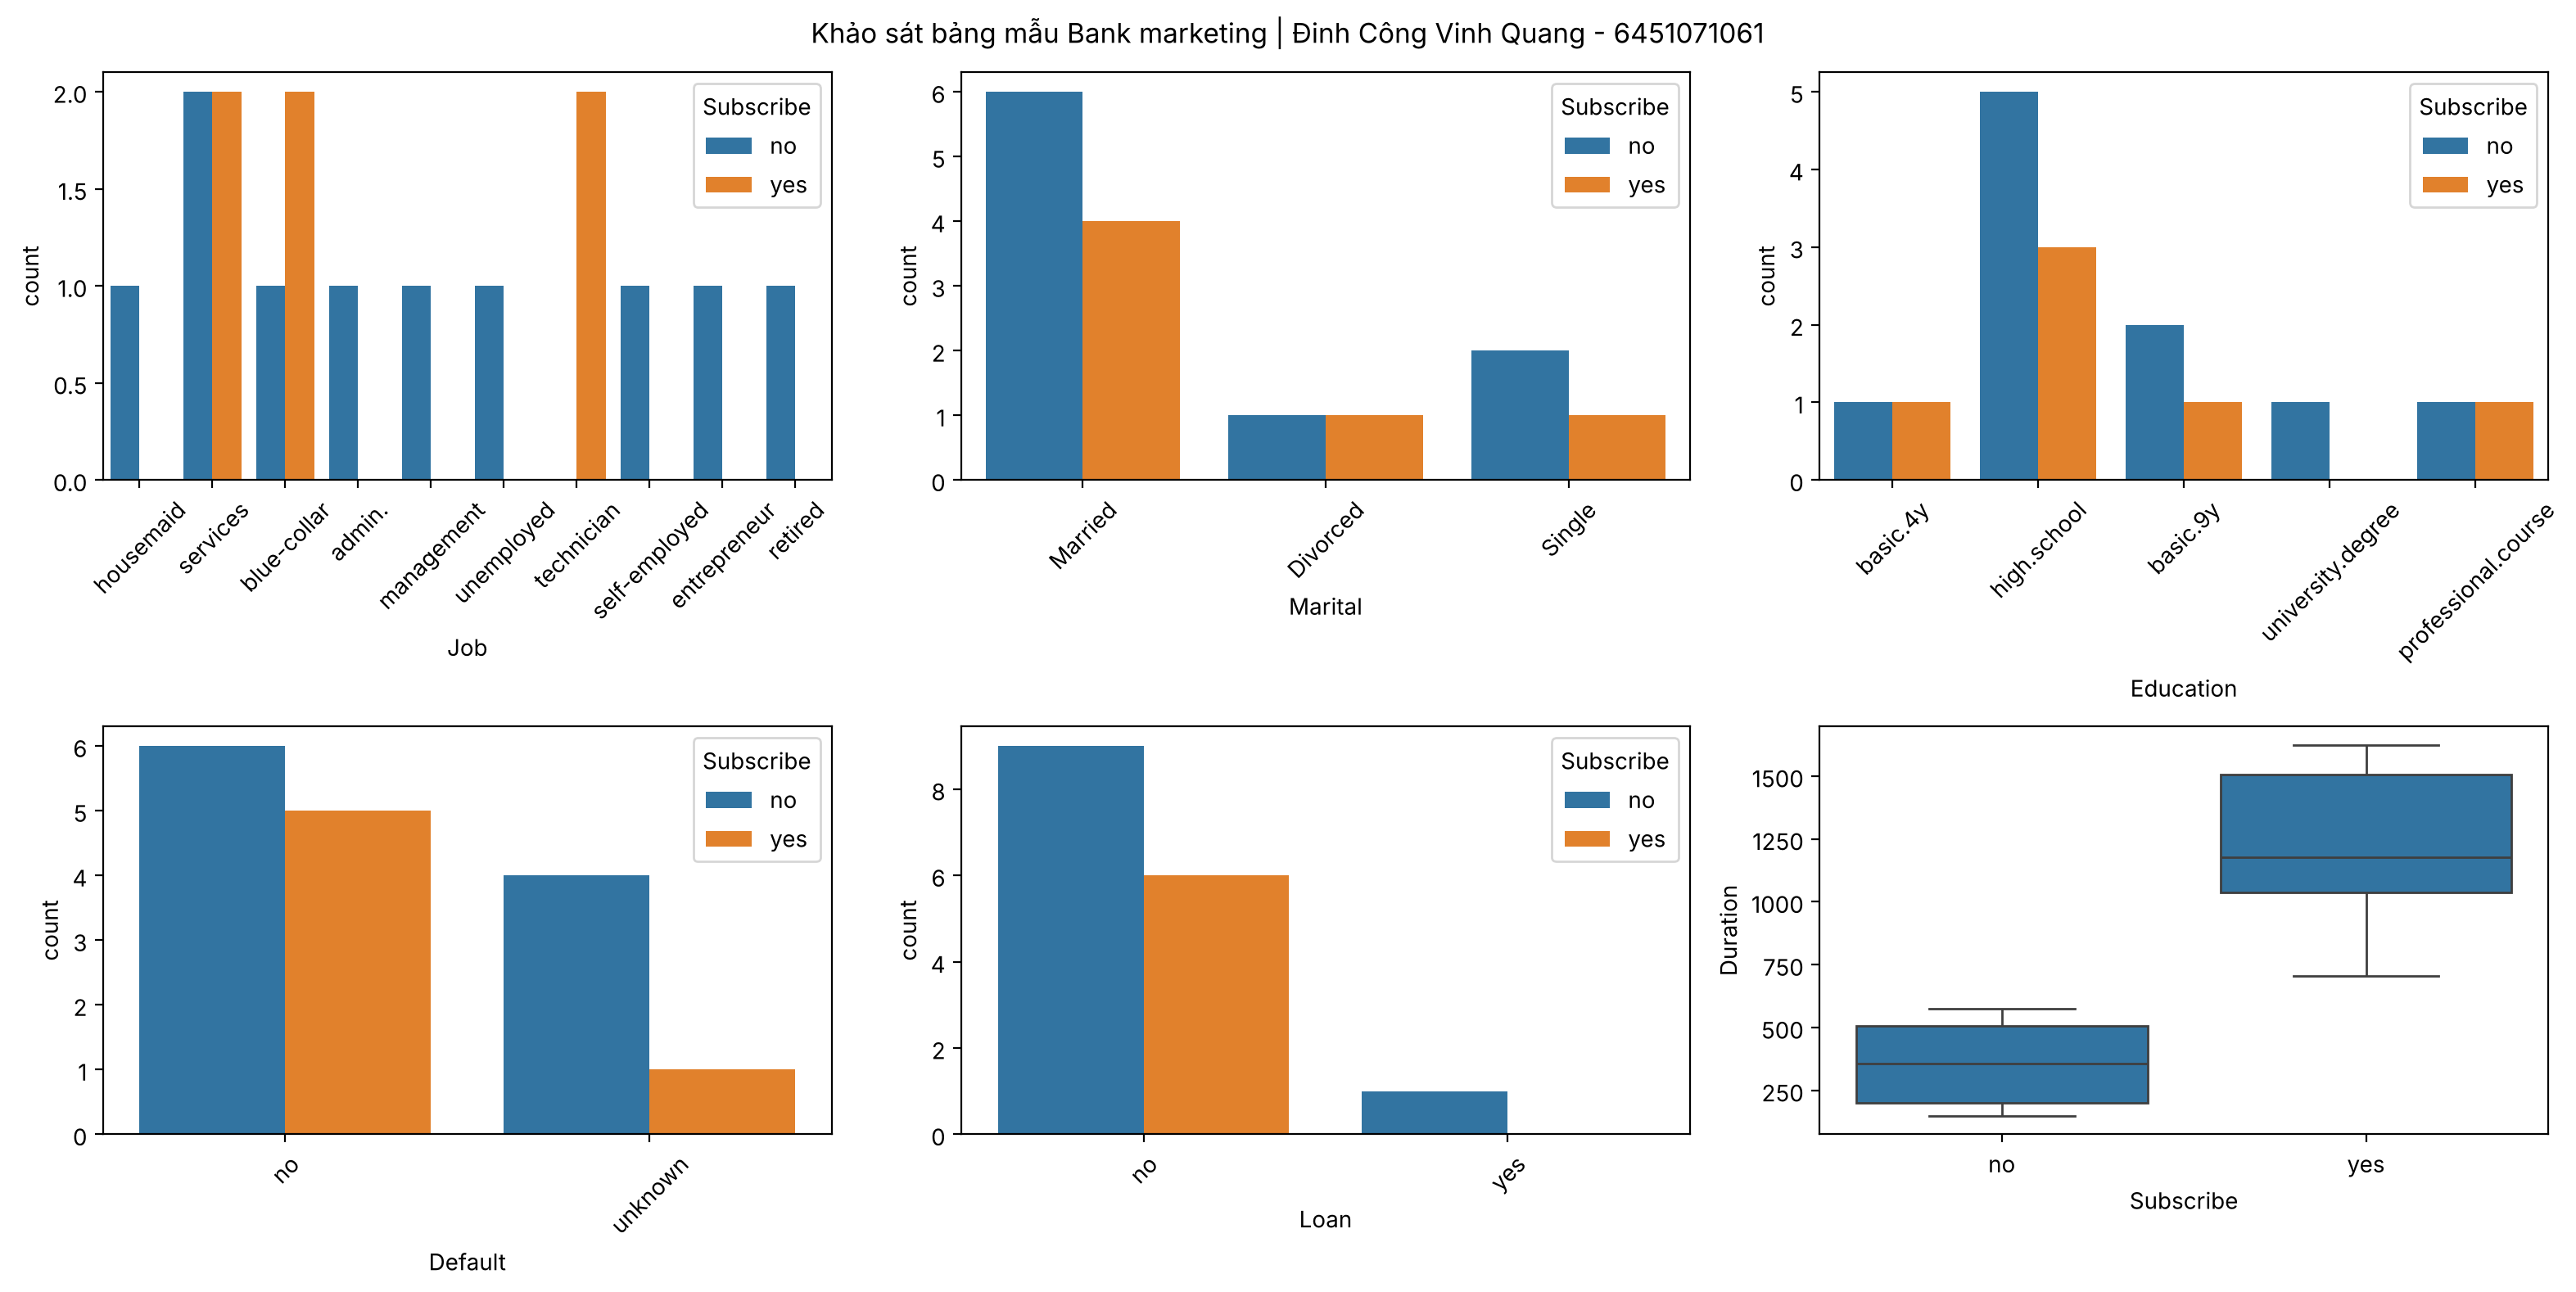

           count    mean    std    min     25%     50%     75%     max
Subscribe                                                             
no          10.0   355.2  168.6  149.0   199.5   357.0   505.0   576.0
yes          6.0  1214.8  352.5  705.0  1037.2  1178.0  1505.5  1623.0


In [6]:
# khảo sát liên quan giữa các thuộc tính và Subscribe
df["sub"] = (df["Subscribe"] == "yes").astype(int)
print(df["Subscribe"].value_counts(), "\n")
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), ["Job", "Marital", "Education", "Default", "Loan"]):
    sns.countplot(data=df, x=c, hue="Subscribe", ax=ax)
    ax.tick_params(axis="x", rotation=45)
sns.boxplot(data=df, x="Subscribe", y="Duration", ax=axes[1, 2])
fig.suptitle(f"Khảo sát bảng mẫu Bank marketing | {HO_TEN} - {MSSV}")
plt.tight_layout(); plt.show()
print(df.groupby("Subscribe")["Duration"].describe().round(1))

**Nhận xét:** trong 16 mẫu có 6 mẫu đăng ký (yes) và 10 mẫu không đăng ký (no).
`Duration` là thuộc tính liên quan rõ nhất: các mẫu đăng ký đều có thời lượng liên lạc từ 705 giây trở lên (trung vị ~1178 s), trong khi các mẫu không đăng ký chủ yếu dưới 600 giây (trung vị ~357 s).
Các thuộc tính còn lại (Job, Marital, Education, Loan) có quá ít mẫu để kết luận chắc chắn; riêng người đã có khoản vay (`Loan = yes`) chỉ có 1 mẫu và không đăng ký.

In [7]:
# ---------------- TIỀN XỬ LÝ ----------------
data = df.drop(columns=["sub"]).copy()

# 1) Cons.price.idx thiếu 1 giá trị -> điền bằng trung bình của cùng nhóm Subscribe (cách thứ hai trong hướng dẫn)
print("Trung bình toàn bộ:", round(data["Cons.price.idx"].mean(), 4))
data["Cons.price.idx"] = data["Cons.price.idx"].fillna(data.groupby("Subscribe")["Cons.price.idx"].transform("mean"))

# 2) Marital thiếu -> điền giá trị xuất hiện nhiều nhất (mode); Default 'unknown' -> xem là một loại mới (giữ nguyên)
data["Marital"] = data["Marital"].fillna(data["Marital"].mode()[0])
print("Giá trị rỗng còn lại:", int(data.isnull().sum().sum()))

# 3) Binning Duration: độ rộng 500 giây -> (0,500], (500,1000], (1000,1500], (1500,2000]; sau đó smoothing bằng trung bình giỏ
data["Duration_bin"] = pd.cut(data["Duration"], bins=[0, 500, 1000, 1500, 2000])
data["Duration_smooth"] = data.groupby("Duration_bin", observed=True)["Duration"].transform("mean").round(1)
display(data[["Duration", "Duration_bin", "Duration_smooth"]].head(8))

Trung bình toàn bộ: 93.8301
Giá trị rỗng còn lại: 0


,Duration,Duration_bin,Duration_smooth
0,261,"(0, 500]",268.0
1,149,"(0, 500]",268.0
2,1575,"(1500, 2000]",1599.0
3,338,"(0, 500]",268.0
4,179,"(0, 500]",268.0
5,1030,"(1000, 1500]",1128.7
6,149,"(0, 500]",268.0
7,424,"(0, 500]",268.0


In [8]:
# 4) Min-max normalization: new = (value - min) / (max - min)
for c in ["Duration", "Cons.price.idx"]:
    data[c + "_norm"] = ((data[c] - data[c].min()) / (data[c].max() - data[c].min())).round(4)

# 5) mã hóa Subscribe và One-hot encoding cho các thuộc tính định tính
data["Subscribe"] = data["Subscribe"].map({"no": 0, "yes": 1})
final = pd.get_dummies(data.drop(columns=["Duration_bin"]), columns=["Job", "Marital", "Education", "Default", "Loan"], dtype=int)
print("Kích thước sau tiền xử lý:", final.shape)
final

Kích thước sau tiền xử lý: (16, 28)


,Duration,Cons.price.idx,Subscribe,Duration_smooth,Duration_norm,Cons.price.idx_norm,Job_admin.,Job_blue-collar,Job_entrepreneur,Job_housemaid,...,Marital_Single,Education_basic.4y,Education_basic.9y,Education_high.school,Education_professional.course,Education_university.degree,Default_no,Default_unknown,Loan_no,Loan_yes
0,261,93.994000,0,268.0,0.0760,1.0000,0,0,0,1,...,0,1,0,0,0,0,1,0,1,0
1,149,93.994000,0,268.0,0.0000,1.0000,0,0,0,0,...,0,0,0,1,0,0,0,1,1,0
2,1575,93.994000,1,1599.0,0.9674,1.0000,0,1,0,0,...,0,1,0,0,0,0,0,1,1,0
3,338,93.994000,0,268.0,0.1282,1.0000,1,0,0,0,...,1,0,0,1,0,0,1,0,1,0
4,179,93.994000,0,268.0,0.0204,1.0000,0,1,0,0,...,1,0,1,0,0,0,1,0,1,0
5,1030,93.994000,1,1128.7,0.5977,1.0000,0,0,0,0,...,0,0,0,1,0,0,1,0,1,0
6,149,93.897333,0,268.0,0.0000,0.8783,0,0,0,0,...,0,0,0,1,0,0,0,1,1,0
7,424,93.994000,0,268.0,0.1866,1.0000,0,0,0,0,...,0,0,0,0,0,1,0,1,1,0
8,1623,93.994000,1,1599.0,1.0000,1.0000,0,0,0,0,...,0,0,0,0,1,0,1,0,1,0
9,568,93.994000,0,595.2,0.2843,1.0000,0,0,0,0,...,0,0,0,1,0,0,0,1,1,0
